In [39]:
import pandas as pd

In [40]:


# Load your Excel file (including the extension)
df = pd.read_excel("/Users/karma/Desktop/Radio_project/CHHA_catalog_full (1).xlsx")



In [41]:
df.head()

,FileName,FolderPath,CategoryFolder,SizeMB,Bitrate,Duration,EmbeddedTitle,EmbeddedArtist,Genre,Year,MD5Hash,LastModified,FullPath
0,220_HORACIO BIGOLIN_Promo Olvera.wav,D:\D,D,4.41,?1411kbps,00:00:26,NaN,NaN,NaN,NaN,1A46A8D81DB44CB96CCB4B273990D073,2023-11-28 14:40:00,D:\D\220_HORACIO BIGOLIN_Promo Olvera.wav
1,HDSM T2 ep27 - pescando 01.mp3,D:\D,D,10.22,?128kbps,00:11:09,NaN,NaN,Blues,2025.0,9F2DF8F47BB9DCF91003626632D3888A,2025-08-27 15:35:00,D:\D\HDSM T2 ep27 - pescando 01.mp3
2,HDSM T2 ep27 - pescando 02.mp3,D:\D,D,11.31,?128kbps,00:12:20,NaN,NaN,Blues,2025.0,094DD43CD7C01C9F3474BEDF39D7494B,2025-08-27 15:35:00,D:\D\HDSM T2 ep27 - pescando 02.mp3
3,SPOT - Mons Hernaan Astudillo.mp3,D:\D\19 aniversario,19 aniversario,0.72,?128kbps,00:00:43,NaN,NaN,Blues,2023.0,6FDABCD3AB7069C43B45AE53449EFC65,2023-11-21 14:24:00,D:\D\19 aniversario\SPOT - Mons Hernaan Astudi...
4,Amanda Martinez.m4a,D:\D\19 aniversario\Voces artistas,Voces artistas,0.26,?66kbps,00:00:32,Amanda Martinez CHHA,NaN,NaN,NaN,407077BD4160A279BBF848F9AD6E5C6A,2023-11-23 06:44:00,D:\D\19 aniversario\Voces artistas\Amanda Mart...


In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 126302 entries, 0 to 126301
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   FileName        126286 non-null  str           
 1   FolderPath      126302 non-null  str           
 2   CategoryFolder  126301 non-null  object        
 3   SizeMB          126302 non-null  float64       
 4   Bitrate         125619 non-null  str           
 5   Duration        125616 non-null  object        
 6   EmbeddedTitle   85038 non-null   object        
 7   EmbeddedArtist  71684 non-null   object        
 8   Genre           81065 non-null   object        
 9   Year            51135 non-null   float64       
 10  MD5Hash         125036 non-null  str           
 11  LastModified    126302 non-null  datetime64[us]
 12  FullPath        126302 non-null  str           
dtypes: datetime64[us](1), float64(2), object(5), str(5)
memory usage: 12.5+ MB


In [43]:
# Select and keep only your three specific columns
df = df[['FileName', 'Bitrate', 'MD5Hash']]

# Verify the changes by looking at the new structure
df.head()


,FileName,Bitrate,MD5Hash
0,220_HORACIO BIGOLIN_Promo Olvera.wav,?1411kbps,1A46A8D81DB44CB96CCB4B273990D073
1,HDSM T2 ep27 - pescando 01.mp3,?128kbps,9F2DF8F47BB9DCF91003626632D3888A
2,HDSM T2 ep27 - pescando 02.mp3,?128kbps,094DD43CD7C01C9F3474BEDF39D7494B
3,SPOT - Mons Hernaan Astudillo.mp3,?128kbps,6FDABCD3AB7069C43B45AE53449EFC65
4,Amanda Martinez.m4a,?66kbps,407077BD4160A279BBF848F9AD6E5C6A


In [44]:
# Show null counts for both columns at once
df[['Bitrate', 'MD5Hash']].isnull().sum()


Bitrate     683
MD5Hash    1266
dtype: int64

In [45]:
# Counts how many times an MD5 hash appears more than once
df['MD5Hash'].duplicated().sum()


np.int64(43676)

In [46]:
# Filters your dataset to show all rows with duplicate MD5 values
duplicates = df[df.duplicated(subset=['MD5Hash'], keep=False)]

# Sorts them so matching hashes sit right next to each other
duplicates.sort_values(by='MD5Hash').head()


,FileName,Bitrate,MD5Hash
84681,INYECCION - DIEGO.mp3,?192kbps,0000D5119E15E959ECAFD3966285D788
84674,INYECCION - DIEGO.mp3,?192kbps,0000D5119E15E959ECAFD3966285D788
110351,Amaral - Salir Corriendo.mp3,?128kbps,0001D8FCC5D93A2F081321C4B0C3E9C0
110410,Amaral - Salir Corriendo.mp3,?128kbps,0001D8FCC5D93A2F081321C4B0C3E9C0
110274,Amaral - Salir Corriendo.mp3,?128kbps,0001D8FCC5D93A2F081321C4B0C3E9C0


In [47]:
# 1. Count how many times each individual hash appears
hash_counts = df['MD5Hash'].value_counts()

# 2. Group those frequencies to see the distribution of duplicates
hash_counts.value_counts()


count
1     56733
2     17102
3      5072
4      2252
5       619
7       291
6       265
8        92
9        84
11       26
10       22
12       21
15        8
14        8
13        6
17        5
16        3
21        2
20        2
19        2
49        1
48        1
43        1
40        1
38        1
29        1
28        1
24        1
23        1
18        1
Name: count, dtype: int64

In [52]:
# Remove duplicate hashes, keeping the first occurrence and removing the rest
df_no_duplicates = df.drop_duplicates(subset=['MD5Hash'], keep='first')

# Check the new shape of your dataset
df_no_duplicates.info()


<class 'pandas.DataFrame'>
Index: 82626 entries, 0 to 126301
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   FileName  82614 non-null  str  
 1   Bitrate   82005 non-null  str  
 2   MD5Hash   82625 non-null  str  
dtypes: str(3)
memory usage: 2.5 MB


In [53]:
df_no_duplicates.head()

,FileName,Bitrate,MD5Hash
0,220_HORACIO BIGOLIN_Promo Olvera.wav,?1411kbps,1A46A8D81DB44CB96CCB4B273990D073
1,HDSM T2 ep27 - pescando 01.mp3,?128kbps,9F2DF8F47BB9DCF91003626632D3888A
2,HDSM T2 ep27 - pescando 02.mp3,?128kbps,094DD43CD7C01C9F3474BEDF39D7494B
3,SPOT - Mons Hernaan Astudillo.mp3,?128kbps,6FDABCD3AB7069C43B45AE53449EFC65
4,Amanda Martinez.m4a,?66kbps,407077BD4160A279BBF848F9AD6E5C6A


In [54]:
df_no_duplicates.shape

(82626, 3)

In [55]:
# 1. Ensure the Bitrate column is converted to a number (extracting digits just in case)
df_no_duplicates['Bitrate_Num'] = df_no_duplicates['Bitrate'].astype(str).str.extract(r'(\d+)').astype(float)

# 2. Filter to KEEP only files strictly greater than 128kbps
df_cleaned_final = df_no_duplicates[df_no_duplicates['Bitrate_Num'] > 128]

# 3. Check the final number of remaining rows and columns
df_cleaned_final.shape


(45518, 4)

/var/folders/qg/p23ghzqj0218qvlmby0w_7qc0000gn/T/ipykernel_93456/2870779975.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=categories, y=counts, palette=["#cccccc", "#2b5c8f"])


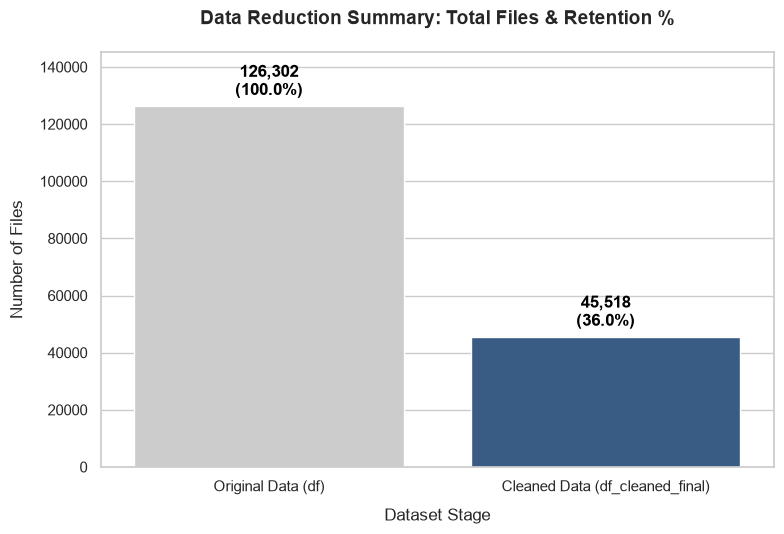

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate values
count_original = len(df)
count_cleaned = len(df_cleaned_final)

pct_original = 100.0
pct_cleaned = (count_cleaned / count_original) * 100

categories = ['Original Data (df)', 'Cleaned Data (df_cleaned_final)']
counts = [count_original, count_cleaned]
percentages = [pct_original, pct_cleaned]

# 2. Set style and figure size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5.5))

# 3. Create the bar chart (using counts for the bar heights)
ax = sns.barplot(x=categories, y=counts, palette=["#cccccc", "#2b5c8f"])

# 4. Loop through the bars to add custom dual labels (Count + Percent)
for i, p in enumerate(ax.patches):
    height = p.get_height()
    # Format string to display: "Count \n (Percentage%)"
    label_text = f'{int(height):,}\n({percentages[i]:.1f}%)'
    
    ax.annotate(label_text, 
                (p.get_x() + p.get_width() / 2., height), 
                ha='center', va='baseline', fontsize=12, color='black', 
                xytext=(0, 8), textcoords='offset points', weight='bold')

# 5. Add titles and labels
plt.title('Data Reduction Summary: Total Files & Retention %', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Dataset Stage', fontsize=12, labelpad=10)
plt.ylabel('Number of Files', fontsize=12, labelpad=10)

# Expand the top of the Y-axis slightly so labels don't get cut off
plt.ylim(0, max(counts) * 1.15)

# Adjust layout and render
plt.tight_layout()
plt.show()
